In [27]:
# Requirements install
%pip install numpy pandas matplotlib seaborn scikit-learn torch imbalanced-learn

# Imports
import seaborn, sklearn, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imblearn

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
import warnings

# Scikit-learn imports
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, KFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score, recall_score, precision_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from scipy.stats import randint
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


warnings.filterwarnings("ignore", category=ConvergenceWarning)

Note: you may need to restart the kernel to use updated packages.


Data loading and preprocessing, data doesn't contain missing feature values so not nessasary to do removal for missing values

In [28]:
# Set a random seed for reproducibility
random_seed = 42
torch.manual_seed(random_seed)
np.random.seed(random_seed)
random.seed(random_seed)

# load the data
spambase_filepath = './data/spambase.data'
data = pd.read_csv(spambase_filepath, header=None)

X = data.iloc[: , :-1] # all rows, all columns except for the label
y = data.iloc[:, -1] # all rows, last column

n_rows, n_features = X.shape # store the number of rows and features

print(f"Number of rows: {n_rows}")
print(f"Number of features: {n_features}")
print(f"Number of spam (1): {y.value_counts()[1]}, not spam (0): {y.value_counts()[0]}")

#arrange into train and test splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed)

#scale using standard scaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#define x and y tensors
X_train_t = torch.Tensor(X_train)
X_test_t = torch.Tensor(X_test)
y_train_t = torch.Tensor(y_train.to_numpy()).view(-1, 1)
y_test_t = torch.Tensor(y_test.to_numpy()).view(-1, 1) 

Number of rows: 4601
Number of features: 57
Number of spam (1): 1813, not spam (0): 2788


In [29]:
# PCA-based feature reduction
pca_components = 20  # choose how many principal components to keep

pca_scaler = StandardScaler()
X_scaled_for_pca = pca_scaler.fit_transform(X)

pca = PCA(n_components=pca_components, random_state=random_seed)
X_pca = pca.fit_transform(X_scaled_for_pca)

print("Explained variance ratio by component:")
for idx, ratio in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"Component {idx}: {ratio:.4f}")
print(f"Total explained variance captured: {pca.explained_variance_ratio_.sum():.4f}")
print(f"Transformed feature matrix shape: {X_pca.shape}")

# Transformed feature matrix ready for downstream models

Explained variance ratio by component:
Component 1: 0.1156
Component 2: 0.0573
Component 3: 0.0351
Component 4: 0.0283
Component 5: 0.0271
Component 6: 0.0257
Component 7: 0.0248
Component 8: 0.0241
Component 9: 0.0227
Component 10: 0.0224
Component 11: 0.0213
Component 12: 0.0198
Component 13: 0.0195
Component 14: 0.0192
Component 15: 0.0191
Component 16: 0.0187
Component 17: 0.0184
Component 18: 0.0180
Component 19: 0.0178
Component 20: 0.0176
Total explained variance captured: 0.5726
Transformed feature matrix shape: (4601, 20)


Calculation for majority vote baseline

In [30]:
majority_class = y.value_counts().idxmax()
baseline_accuracy = (y == majority_class).mean()

print(f"Baseline accuracy: {baseline_accuracy:.3f}")

Baseline accuracy: 0.606


Training using Logistic Regression

In [31]:
EPOCH_LR = 100 

def make_lr_model(config, *, for_epoch_training=False, max_iter=1000):
    params = {
        "solver": "saga",
        "random_state": random_seed,
        "penalty": config["penalty"],
        "C": config["C"],
        "max_iter": max_iter,
        "warm_start": False,
    }
    if config.get("l1_ratio") is not None:
        params["l1_ratio"] = config["l1_ratio"]
    if for_epoch_training:
        params["max_iter"] = 1
        params["warm_start"] = True
    return LogisticRegression(**params)

lr_search_space = [
    {"name": "L2_C1.0", "penalty": "l2", "C": 1.0},
    {"name": "L2_C0.2", "penalty": "l2", "C": 0.2},
    {"name": "L1_C0.5", "penalty": "l1", "C": 0.5},
    {"name": "ElasticNet_C0.8_l1_0.5", "penalty": "elasticnet", "C": 0.8, "l1_ratio": 0.5},
]

def train_logistic_regression(model, epoch_lr):
    train_loss, test_loss, test_acc, epochs = [], [], [], []

    for epoch in range(epoch_lr):

        model.fit(X_train, y_train)

        #Record loss and accuracy every 5 epoch
        if epoch%5 == 0:
            y_pred = model.predict_proba(X_train)[:, 1]
            y_pred_t = model.predict_proba(X_test)[:, 1]
            loss = log_loss(y_train, y_pred)
            loss_t = log_loss(y_test, y_pred_t)
            acc = model.score(X_test, y_test)

            train_loss.append(loss)
            test_loss.append(loss_t)   
            test_acc.append(acc)
            epochs.append(epoch) 

    return train_loss, test_loss, test_acc, epochs

best_run = None

for config in lr_search_space:
    model_lr = make_lr_model(config, for_epoch_training=True)
    history = train_logistic_regression(model_lr, EPOCH_LR)
    final_accuracy = history[2][-1]
    ratio_msg = f", l1_ratio={config['l1_ratio']}" if config.get('l1_ratio') is not None else ''
    print(f"{config['name']}: penalty={config['penalty']}, C={config['C']}{ratio_msg} -> Test Accuracy: {final_accuracy:.3f}")
    if not best_run or final_accuracy > best_run['final_accuracy']:
        best_run = {
            "config": config,
            "history": history,
            "final_accuracy": final_accuracy
        }

train_loss_lr, test_loss_lr, acc_lr, epoch_lr = best_run["history"]
best_lr_config = best_run["config"]
print(f"Selected logistic regression config: {best_lr_config['name']} (penalty={best_lr_config['penalty']}, C={best_lr_config['C']}) with test accuracy {best_run['final_accuracy']:.3f}")


L2_C1.0: penalty=l2, C=1.0 -> Test Accuracy: 0.902
L2_C0.2: penalty=l2, C=0.2 -> Test Accuracy: 0.899
L1_C0.5: penalty=l1, C=0.5 -> Test Accuracy: 0.902
ElasticNet_C0.8_l1_0.5: penalty=elasticnet, C=0.8, l1_ratio=0.5 -> Test Accuracy: 0.903
Selected logistic regression config: ElasticNet_C0.8_l1_0.5 (penalty=elasticnet, C=0.8) with test accuracy 0.903


Graph train and test loss, anc test accuracy

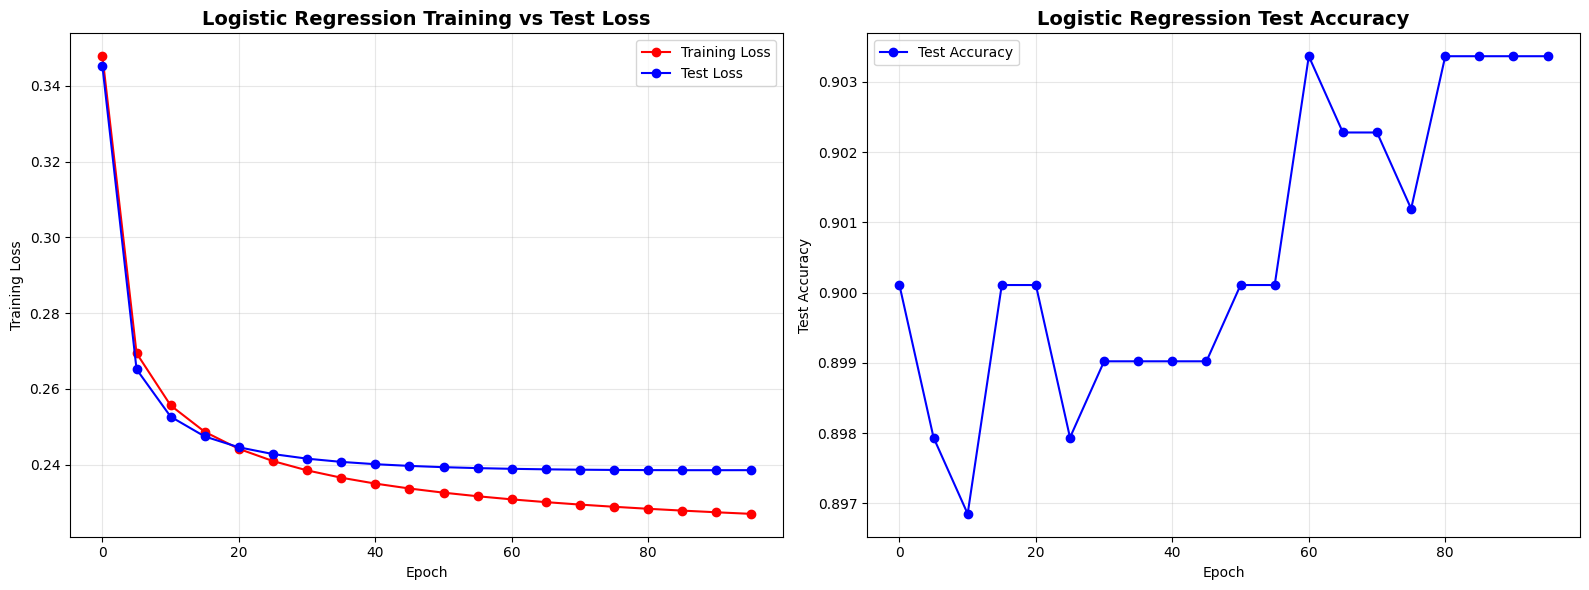

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(epoch_lr, train_loss_lr, label='Training Loss', color='red', marker='o')
axes[0].plot(epoch_lr, test_loss_lr, label='Test Loss', color='blue', marker='o')
axes[0].set_title('Logistic Regression Training vs Test Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epoch_lr, acc_lr, label='Test Accuracy', color='blue', marker='o')
axes[1].set_title('Logistic Regression Test Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Test Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Training using Neural Network

In [33]:
#define some constants for neural network training
LR_NN = 0.005
EPOCH_NN = 150
WEIGHT_DECAY_NN = 1e-4
DROPOUT_P = 0.2

#define neural network class
class NeuralNetwork(nn.Module):
    def __init__(self, features, dropout):
        super().__init__()
        self.flatten = nn.Flatten()
        self.stack = nn.Sequential(
            nn.Linear(features, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16,1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.stack(x)
    
    
def train_neural_network(model, criterion, optimizer, epoch_nn, scheduler=None, X_train_t=X_train_t, y_train_t=y_train_t, X_test_t=X_test_t, y_test_t=y_test_t):
    train_loss, test_loss, test_acc, epochs = [], [], [], []

    model.train()
    #training loop
    for epoch in range(epoch_nn):
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)

        #compute gradients, update parameters
        loss.backward()
        optimizer.step()

        if scheduler is not None: #Learning rate would be None if no scheduler is used
            scheduler.step()

        if epoch%5 == 0:
            model.eval()

            with torch.no_grad():
                y_pred = model(X_test_t)
                y_pred_binary = (y_pred >= 0.5).int()
                acc = accuracy_score(y_test_t, y_pred_binary)
                loss_t = criterion(y_pred, y_test_t)

                train_loss.append(loss.item())
                test_loss.append(loss_t.item())
                test_acc.append(acc) 
                epochs.append(epoch)
            
            model.train()

    return train_loss, test_loss, test_acc, epochs

# hyperparameter tuning for neural network
def nn_hyperparameter_tuning(iter):

    best_wd = None
    best_dp = None
    best_gamma = None
    best_step = None
    best_acc = 0

    kf = KFold(n_splits=5, shuffle=True)

    for i in range(iter):
        wd = 10**random.uniform(-5, -3)
        dp = random.uniform(0.1, 0.5)
        gamma = random.uniform(0.1, 0.9)
        step = random.randint(10, 50)
        fold_acc = []

        for j, (train_index, val_index) in enumerate(kf.split(X_train_t)):
            X_train_fold, X_val_fold = X_train_t[train_index], X_train_t[val_index]
            y_train_fold, y_val_fold = y_train_t[train_index], y_train_t[val_index]

            model_nn = NeuralNetwork(n_features, dp)
            criterion = nn.BCELoss()
            optimizer = optim.Adam(model_nn.parameters(), LR_NN, weight_decay=wd)
            scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=step, gamma=gamma)

            train_loss, test_loss, acc, epoch = train_neural_network(model_nn, criterion, optimizer, EPOCH_NN, scheduler, X_train_fold, y_train_fold, X_val_fold, y_val_fold)
            final_acc = acc[-1]
            fold_acc.append(final_acc)
        
        avg_acc = sum(fold_acc) / len(fold_acc)
        if avg_acc > best_acc:
            best_acc = avg_acc
            best_wd = wd
            best_dp = dp
            best_gamma = gamma
            best_step = step

    return best_wd, best_dp, best_acc, best_gamma, best_step

best_wd, best_dp, best_acc, best_gamma, best_step = nn_hyperparameter_tuning(10)
print(f"Selected neural network hyperparameters: weight_decay={best_wd:.6f}, dropout_p={best_dp:.3f} with average cross-validation accuracy {best_acc:.3f}, gamma={best_gamma:.3f}, step_size={best_step}")

#instantiate model, criterion, and optimizer
model_nn = NeuralNetwork(n_features, best_dp)
criterion_nn = nn.BCELoss()
optimizer_nn = optim.Adam(model_nn.parameters(), LR_NN, weight_decay=best_wd)
scheduler_nn = optim.lr_scheduler.StepLR(optimizer_nn, step_size=best_step, gamma=best_gamma)

train_loss_nn, test_loss_nn, acc_nn, epoch_nn = train_neural_network(model_nn, criterion_nn, optimizer_nn, EPOCH_NN, scheduler_nn)


Selected neural network hyperparameters: weight_decay=0.000019, dropout_p=0.141 with average cross-validation accuracy 0.941, gamma=0.693, step_size=44


Plot neural network training loss, test loss, and accuracy

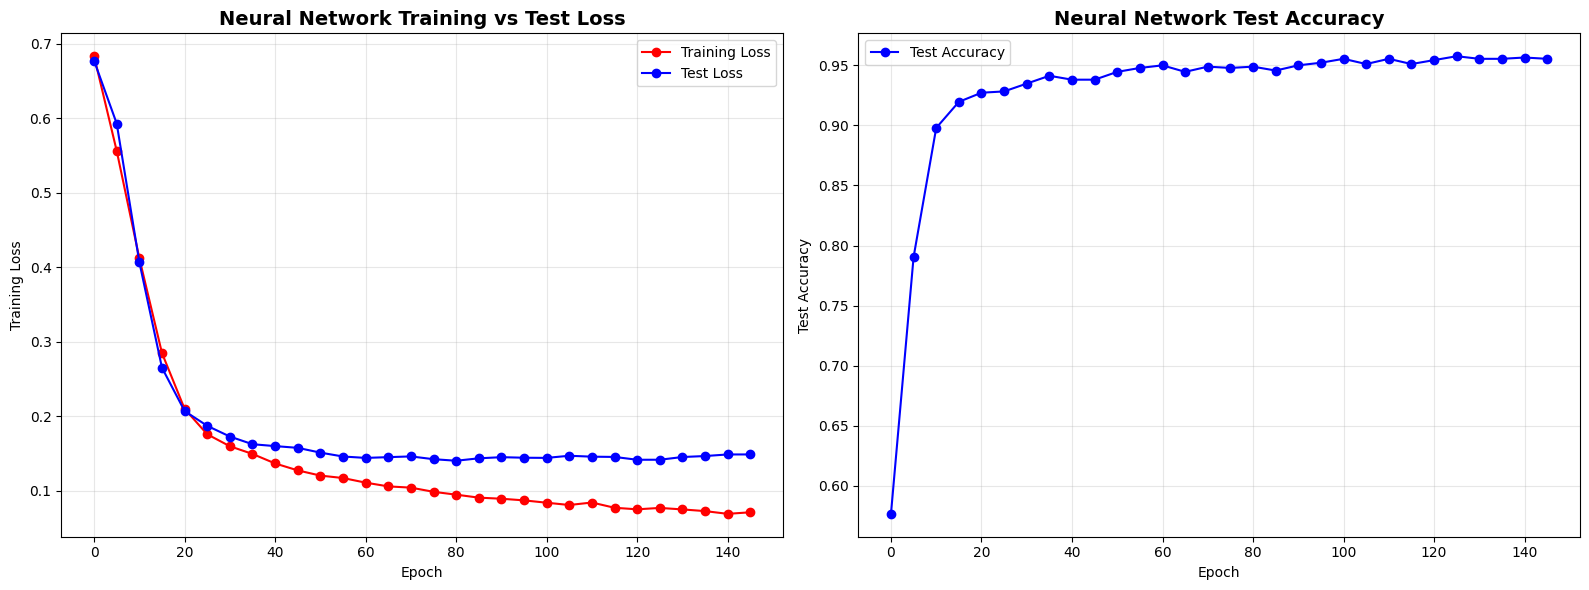

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(epoch_nn, train_loss_nn, label='Training Loss', color='red', marker='o')
axes[0].plot(epoch_nn, test_loss_nn, label='Test Loss', color='blue', marker='o')
axes[0].set_title('Neural Network Training vs Test Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epoch_nn, acc_nn, label='Test Accuracy', color='blue', marker='o')
axes[1].set_title('Neural Network Test Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Test Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Train random forest classifier model

In [35]:
RF_PARAMS = {
    "n_estimators": randint(100, 300),
    "max_depth": randint(3, 12),
    "min_samples_split": randint(2, 10),
    "min_samples_leaf": randint(1, 5),
    #"max_features": "sqrt"
}

rf_model = RandomForestClassifier(**RF_PARAMS, random_state=random_seed)

# tuning hyperparameters
clf = RandomizedSearchCV(rf_model, RF_PARAMS, cv=5, n_iter=10, random_state=random_seed)
clf.fit(X_train, y_train)

print(f"Best Random Forest parameters: {clf.best_params_}")

bestrf_model = RandomForestClassifier(**clf.best_params_, random_state=random_seed)
bestrf_model.fit(X_train, y_train)

acc_rf = bestrf_model.score(X_test, y_test)
print(f"Random Forest accuracy: {acc_rf:.3f}")


Best Random Forest parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 202}
Random Forest accuracy: 0.940


In [36]:
log_reg_voter = make_lr_model(best_lr_config)
rf_voter = RandomForestClassifier(**clf.best_params_, random_state=random_seed + 1)
gb_voter = GradientBoostingClassifier(random_state=random_seed)

voting_clf = VotingClassifier(
    estimators=[
        ('lr', log_reg_voter),
        ('rf', rf_voter),
        ('gb', gb_voter)
    ],
    voting='soft',
    weights=[2, 1, 2]
)

voting_clf.fit(X_train, y_train)
acc_voting = voting_clf.score(X_test, y_test)
print(f"Voting ensemble accuracy: {acc_voting:.3f}")


Voting ensemble accuracy: 0.946


SMOTE implementation

Neural Network accuracy: 0.955 Neural Network (SMOTE) accuracy: 0.952
Random Forest accuracy: 0.940 Random Forest (SMOTE) accuracy: 0.941


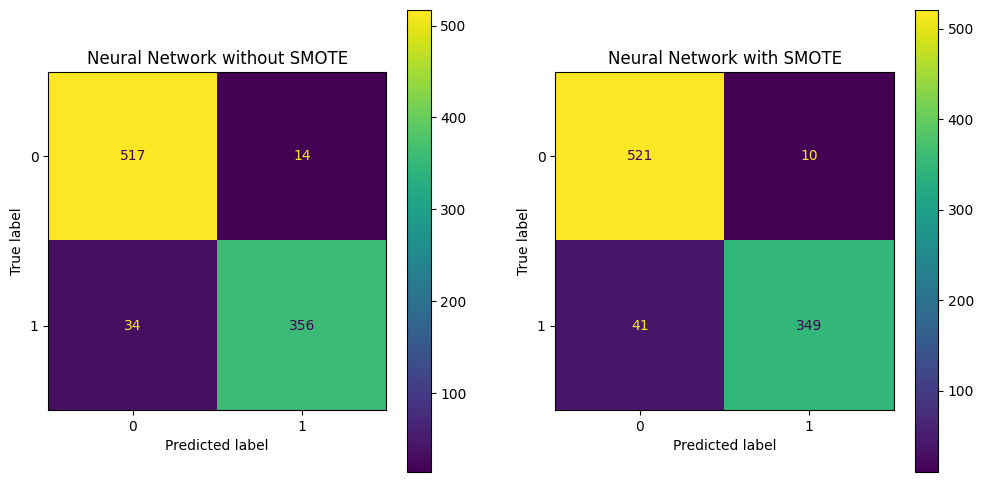

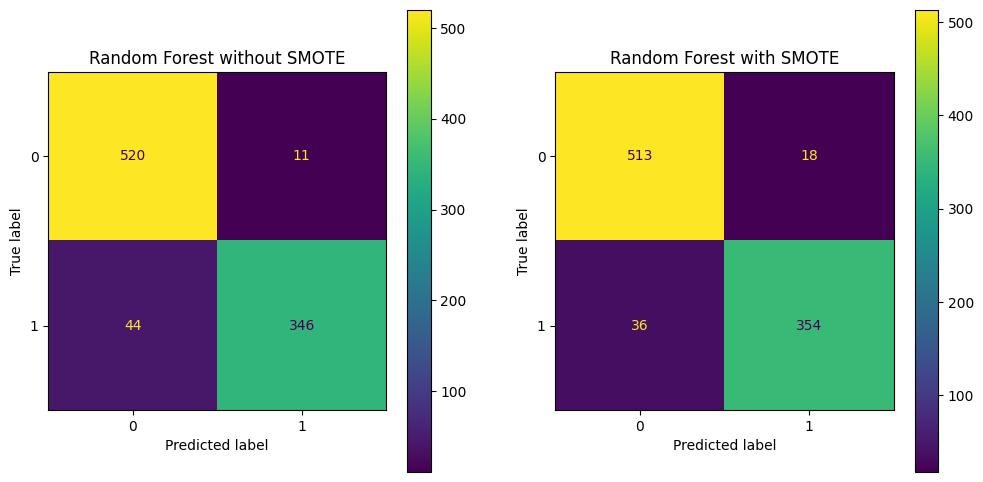

In [37]:
sm = SMOTE(random_state=random_seed)
X_res, y_res = sm.fit_resample(X_train, y_train)

# neural network with resampled data
X_res_t = torch.Tensor(X_res)
y_res_t = torch.Tensor(y_res.to_numpy()).view(-1, 1)

model_nn_smote = NeuralNetwork(n_features, best_dp)
optimizer_nn_smote = optim.Adam(model_nn_smote.parameters(), LR_NN, weight_decay=best_wd)
scheduler_nn_smote = optim.lr_scheduler.StepLR(optimizer_nn_smote, step_size=best_step, gamma=best_gamma)

train_loss_nn_smote, test_loss_nn_smote, acc_nn_smote, epoch_nn_smote = train_neural_network(model_nn_smote, criterion_nn, optimizer_nn_smote, EPOCH_NN, scheduler_nn_smote)

# random forest with resampled data
bestrf_model_smote = RandomForestClassifier(**clf.best_params_, random_state=random_seed)
bestrf_model_smote.fit(X_res, y_res)

# confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

y_pred_nn = model_nn(X_test_t)
cm_nn = confusion_matrix(y_test, (y_pred_nn >= 0.5).int())
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn)
disp.plot(ax=axes[0])
axes[0].set_title("Neural Network without SMOTE")

y_pred_nn_smote = model_nn_smote(X_test_t)
cm_nn_smote = confusion_matrix(y_test, (y_pred_nn_smote >= 0.5).int())
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn_smote)
disp.plot(ax=axes[1])
axes[1].set_title("Neural Network with SMOTE")

# random forest with resampled data
fig1, axes = plt.subplots(1, 2, figsize=(12, 6))

y_pred_rf = bestrf_model.predict(X_test)
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp.plot(ax=axes[0])
axes[0].set_title("Random Forest without SMOTE")

y_pred_rf_smote = bestrf_model_smote.predict(X_test)
cm_rf_smote = confusion_matrix(y_test, y_pred_rf_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote)
disp.plot(ax=axes[1])
axes[1].set_title("Random Forest with SMOTE")

# accuracies
acc_nn_smote = acc_nn_smote[-1]
print(f"Neural Network accuracy: {acc_nn[-1]:.3f} Neural Network (SMOTE) accuracy: {acc_nn_smote:.3f}")
acc_rf_smote = bestrf_model_smote.score(X_test, y_test)
print(f"Random Forest accuracy: {acc_rf:.3f} Random Forest (SMOTE) accuracy: {acc_rf_smote:.3f}")
# undersampling majority?



Compare model accuracy with baseline majority vote performance

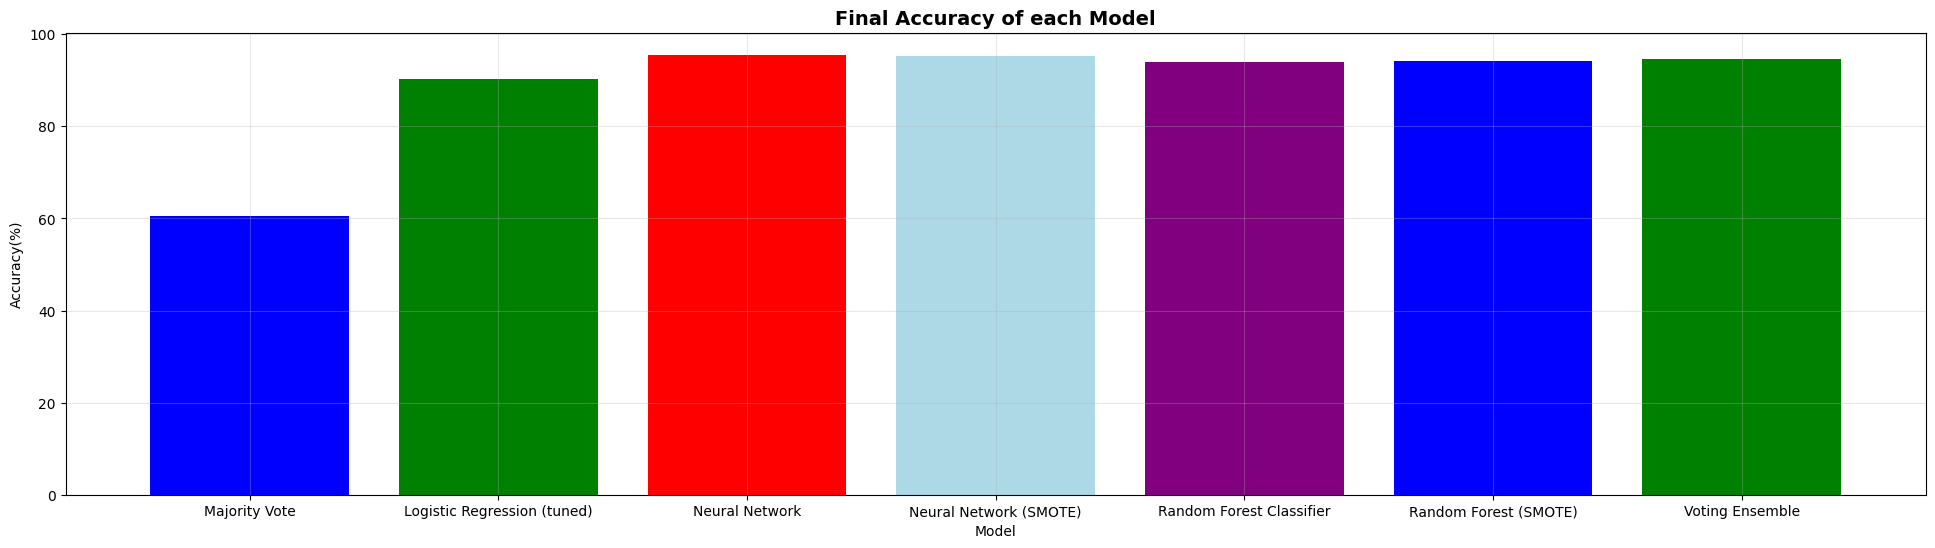

In [38]:
models = ['Majority Vote', 'Logistic Regression (tuned)', 'Neural Network', 'Neural Network (SMOTE)', 'Random Forest Classifier', 'Random Forest (SMOTE)', 'Voting Ensemble']
accuracy = [baseline_accuracy*100, acc_lr[-1]*100, acc_nn[-1]*100, acc_nn_smote*100, acc_rf*100, acc_rf_smote*100, acc_voting*100]

plt.figure(figsize=(24, 6))
plt.bar(models, accuracy, color = ['blue', 'green', 'red', 'lightblue', 'purple'])
plt.title('Final Accuracy of each Model', fontsize=14, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Accuracy(%)')
plt.grid(True, alpha=0.3)

plt.show()


In [39]:
# stratified 5-fold splits
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)

# define each model, evaluate with cross-validation
cv_models = {
    'Logistic Regression (tuned)': make_pipeline(StandardScaler(), make_lr_model(best_lr_config)),
    'Random Forest': RandomForestClassifier(**clf.best_params_, random_state=random_seed),
    'Voting Ensemble': make_pipeline(
        StandardScaler(),
        VotingClassifier(
            estimators=[
                ('lr', make_lr_model(best_lr_config)),
                ('rf', RandomForestClassifier(**clf.best_params_, random_state=random_seed + 3)),
                ('gb', GradientBoostingClassifier(random_state=random_seed + 4))
            ],
            voting='soft',
            weights=[2, 1, 2]
        )
    )
}

cv_results = {}

for name, estimator in cv_models.items():
    scores = cross_val_score(estimator, X, y, cv=skf, scoring='accuracy')
    cv_results[name] = scores
    print(f"{name}: mean accuracy={scores.mean():.3f}, std={scores.std():.3f}")


Logistic Regression (tuned): mean accuracy=0.925, std=0.007
Random Forest: mean accuracy=0.942, std=0.005
Voting Ensemble: mean accuracy=0.945, std=0.004


In [ ]:
# PCA pipelines for each model (StandardScaler -> PCA fitted on training data only)
# Recreate train/test split without touching the already scaled data used above
# https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
#Chatgpt helped with this part
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=random_seed
)

pca_variants = {
    "PCA (20 components)": PCA(n_components=20, random_state=random_seed),
    "PCA (95% variance)": PCA(n_components=0.95, random_state=random_seed)
}

pca_results = {}
pca_meta = {}

for variant_label, pca_estimator in pca_variants.items():
    # Scale then apply PCA on training data, transform test data with the same steps
    variant_scaler = StandardScaler()
    X_train_scaled = variant_scaler.fit_transform(X_train_raw)
    X_test_scaled = variant_scaler.transform(X_test_raw)

    X_train_pca = pca_estimator.fit_transform(X_train_scaled)
    X_test_pca = pca_estimator.transform(X_test_scaled)

    n_pca_features = X_train_pca.shape[1]
    explained_var = pca_estimator.explained_variance_ratio_.sum()

    # Logistic Regression with PCA features
    lr_pca = make_lr_model(best_lr_config)
    lr_pca.fit(X_train_pca, y_train_raw)
    acc_lr_pca = lr_pca.score(X_test_pca, y_test_raw)

    # Neural Network with PCA features
    X_train_pca_t = torch.Tensor(X_train_pca)
    X_test_pca_t = torch.Tensor(X_test_pca)
    y_train_raw_t = torch.Tensor(y_train_raw.to_numpy()).view(-1, 1)
    y_test_raw_t = torch.Tensor(y_test_raw.to_numpy()).view(-1, 1)

    model_nn_pca = NeuralNetwork(n_pca_features, best_dp)
    criterion_pca = nn.BCELoss()
    optimizer_pca = optim.Adam(model_nn_pca.parameters(), LR_NN, weight_decay=best_wd)
    scheduler_pca = optim.lr_scheduler.StepLR(optimizer_pca, step_size=best_step, gamma=best_gamma)

    _, _, acc_nn_history_pca, _ = train_neural_network(
        model_nn_pca,
        criterion_pca,
        optimizer_pca,
        EPOCH_NN,
        scheduler_pca,
        X_train_pca_t,
        y_train_raw_t,
        X_test_pca_t,
        y_test_raw_t
    )
    acc_nn_pca = acc_nn_history_pca[-1]

    # Random Forest with PCA features
    rf_pca = RandomForestClassifier(**clf.best_params_, random_state=random_seed)
    rf_pca.fit(X_train_pca, y_train_raw)
    acc_rf_pca = rf_pca.score(X_test_pca, y_test_raw)

    # Voting Ensemble with PCA features
    voting_pca = VotingClassifier(
        estimators=[
            ('lr', make_lr_model(best_lr_config)),
            ('rf', RandomForestClassifier(**clf.best_params_, random_state=random_seed + 5)),
            ('gb', GradientBoostingClassifier(random_state=random_seed + 6))
        ],
        voting='soft',
        weights=[2, 1, 2]
    )
    voting_pca.fit(X_train_pca, y_train_raw)
    acc_voting_pca = voting_pca.score(X_test_pca, y_test_raw)

    pca_results[variant_label] = {
        'Logistic Regression': acc_lr_pca,
        'Neural Network': acc_nn_pca,
        'Random Forest': acc_rf_pca,
        'Voting Ensemble': acc_voting_pca
    }
    pca_meta[variant_label] = {
        'components': n_pca_features,
        'explained_variance': explained_var
    }

    print(f"{variant_label}: components={n_pca_features}, explained_variance={explained_var:.3f}")
    print(f"    LR={acc_lr_pca:.3f}, NN={acc_nn_pca:.3f}, RF={acc_rf_pca:.3f}, Voting={acc_voting_pca:.3f}")


PCA (20 components): components=20, explained_variance=0.576
    LR=0.906, NN=0.952, RF=0.926, Voting=0.924
PCA (95% variance): components=48, explained_variance=0.955
    LR=0.915, NN=0.942, RF=0.933, Voting=0.934


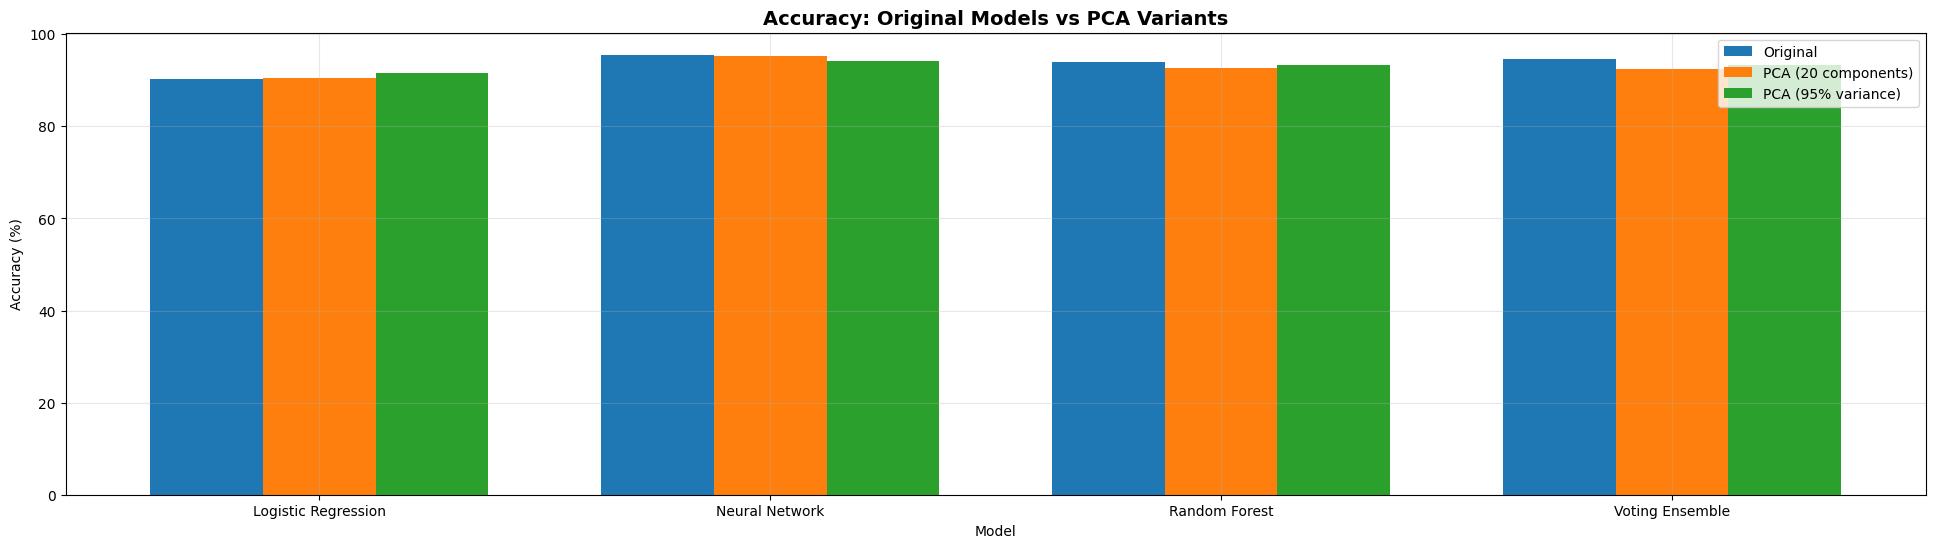

In [41]:
# Bar chart comparing original models to PCA variants
base_model_acc = {
    'Logistic Regression': acc_lr[-1],
    'Neural Network': acc_nn[-1],
    'Random Forest': acc_rf,
    'Voting Ensemble': acc_voting
}

model_names = list(base_model_acc.keys())
variant_labels = list(pca_variants.keys())

x = np.arange(len(model_names))
bar_width = 0.25

plt.figure(figsize=(24, 6))
plt.bar(x, [base_model_acc[m] * 100 for m in model_names], width=bar_width, label='Original')

for idx, variant_label in enumerate(variant_labels, start=1):
    offsets = x + bar_width * idx
    plt.bar(offsets, [pca_results[variant_label][m] * 100 for m in model_names], width=bar_width, label=variant_label)

plt.xticks(x + bar_width * len(variant_labels) / 2, model_names)
plt.title('Accuracy: Original Models vs PCA Variants', fontsize=14, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
